# 5. Classification: who will subscribe to a term deposit?

The question: given what the bank knows about a client before the call, how likely are they to say yes, and who is worth calling?

My first version of this notebook used a random 80/20 split and got a test ROC-AUC of 0.814. Then I trained on earlier calls and tested on later ones, and the same model dropped to 0.658. A bank would use this model on next quarter's calls, not on a random sample of calls it already made, so the time-ordered split is the main result here. The random split is still at the end, because it shows how much of the score only works in-sample.

`duration` is dropped everywhere. Call length is only known after the call ends, so it leaks the answer (notebook 1).

In [1]:
import json
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lightgbm import LGBMClassifier
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, TimeSeriesSplit, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from src import SEED
from src.data import load_bank
from src.modeling import (
    best_threshold,
    cost_curve,
    cost_sensitivity,
    expected_cost,
    time_ordered_split,
    within_group_auc,
)
from src.plotting import ACCENT, COOL, INK_2, save, set_style

set_style()
np.random.seed(SEED)
RESULTS = Path.cwd().parent / "results"
RESULTS.mkdir(exist_ok=True)

bank = load_bank(drop_duration=True)
assert "duration" not in bank.columns

## The campaign changed a lot over time

The file has no dates, but it is in call order, so I can rebuild the calendar month of every call. That makes it easy to see what a random split hides.

In [2]:
# The file has no date column, but it is in call order and `month` only ever moves forward.
# A new calendar month starts wherever `month` changes. The data starts in May 2008.
MONTHS = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
period = (bank["month"] != bank["month"].shift()).cumsum()
month_num = bank["month"].map({mo: i + 1 for i, mo in enumerate(MONTHS)})
year = 2008 + (month_num.diff() < 0).cumsum()
bank["call_month"] = pd.to_datetime(dict(year=year, month=month_num, day=1))
assert period.nunique() == bank["call_month"].nunique()

by_month = bank.groupby("call_month").agg(calls=("subscribed", "size"), rate=("subscribed", "mean"),
                                          nr_employed_values=("nr_employed", "nunique"))
print(f"{len(by_month)} calendar months, {by_month.index.min():%b %Y} to {by_month.index.max():%b %Y}")
print("months where nr_employed takes more than one value:", int((by_month["nr_employed_values"] > 1).sum()))
by_month[["calls", "rate"]].T.round(3)

26 calendar months, May 2008 to Nov 2010
months where nr_employed takes more than one value: 0


call_month,2008-05-01,2008-06-01,2008-07-01,2008-08-01,2008-10-01,2008-11-01,2008-12-01,2009-03-01,2009-04-01,2009-05-01,...,2009-12-01,2010-03-01,2010-04-01,2010-05-01,2010-06-01,2010-07-01,2010-08-01,2010-09-01,2010-10-01,2010-11-01
calls,7763.000,4374.000,6685.000,5175.000,67.000,3616.000,10.0,282.000,2458.00,5794.00,...,172.000,264.000,174.000,212.000,229.000,311.000,233.000,303.000,204.000,128.000
rate,0.031,0.043,0.061,0.052,0.627,0.053,0.1,0.447,0.18,0.09,...,0.512,0.568,0.557,0.575,0.467,0.566,0.515,0.495,0.456,0.453


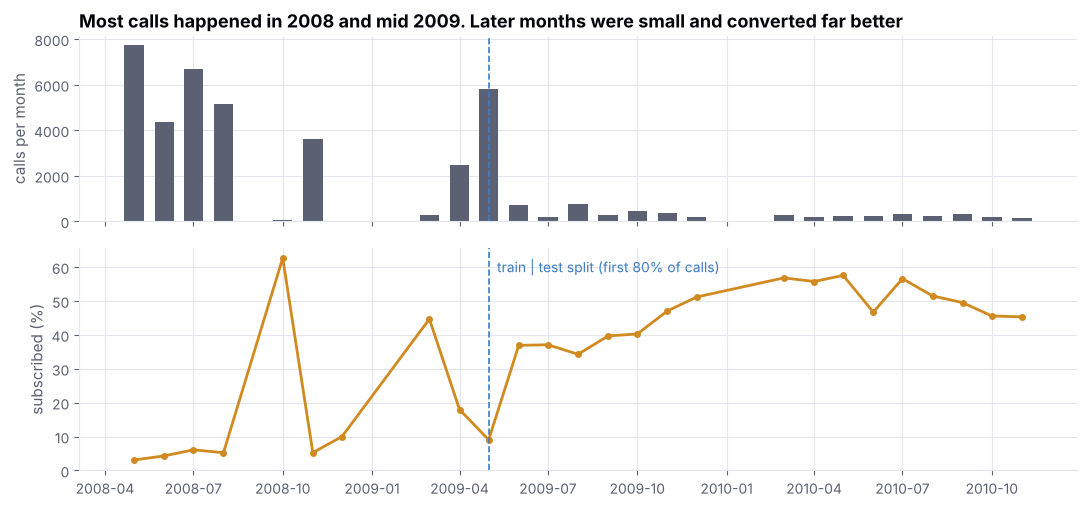

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})
axes[0].bar(by_month.index, by_month["calls"], width=20, color=INK_2)
axes[0].set(ylabel="calls per month", title="Most calls happened in 2008 and mid 2009. Later months were small and converted far better")
axes[1].plot(by_month.index, by_month["rate"] * 100, color=ACCENT, marker="o", markersize=4)
axes[1].set(ylabel="subscribed (%)", ylim=(0, None))
cut_month = bank["call_month"].iloc[int(len(bank) * 0.8)]
for ax in axes:
    ax.axvline(cut_month, color=COOL, linestyle="--", linewidth=1.2)
axes[1].annotate("train | test split (first 80% of calls)", xy=(cut_month, 60), xytext=(6, 0),
                 textcoords="offset points", color=COOL, fontsize=10, va="center")
fig.tight_layout()
save(fig, "bank_drift.png");

The early months had thousands of calls each and converted at 3% to 6%. From mid 2009 the bank made a few hundred calls a month and around half of them converted. Whatever changed (who was on the call list, the economy, the offer), a model trained on 2008 is being asked about a different population.

`nr_employed` takes exactly one value per calendar month, so it is a month label in disguise. The other macro columns are close to that. On a random split the model can learn "calls in month X convert at rate Y" from the training rows of month X and apply it to the test rows of month X. That only works when the test calls come from months the model has already seen.

## Features and models

`pdays` is "days since last contact" and is missing for the 96% of clients never contacted before, so I keep the `previously_contacted` flag plus `previous` and `poutcome` instead. Every preprocessing step lives inside a `Pipeline`, so it is fitted only on whatever rows the model trains on. I compare logistic regression and LightGBM, each with and without the five macro columns.

In [4]:
y = bank["subscribed"]
X = bank.drop(columns=["subscribed", "pdays", "call_month"])
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = [col for col in X.columns if col not in cat_cols]
MACRO = ["emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"]
print("categorical:", cat_cols)
print("numeric:", num_cols)

categorical: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
numeric: ['age', 'campaign', 'previous', 'emp_var_rate', 'cons_price_idx', 'cons_conf_idx', 'euribor3m', 'nr_employed', 'previously_contacted']


In [5]:
def make_model(kind: str, drop: list[str] = ()) -> Pipeline:
    """A full pipeline, so encoding and scaling are fitted only on whatever rows it is trained on."""
    cats = [col for col in cat_cols if col not in drop]
    nums = [col for col in num_cols if col not in drop]
    if kind.startswith("logistic"):
        pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cats),
                                 ("num", StandardScaler(), nums)])
        weight = "balanced" if kind == "logistic (balanced)" else None
        clf = LogisticRegression(max_iter=2000, C=1.0, class_weight=weight)
    else:
        pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cats),
                                 ("num", "passthrough", nums)], verbose_feature_names_out=False)
        if kind == "random forest":
            clf = RandomForestClassifier(n_estimators=400, min_samples_leaf=10, max_features="sqrt",
                                         n_jobs=4, random_state=SEED)
        else:
            clf = LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=50,
                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                                 random_state=SEED, verbose=-1, n_jobs=4)
    return Pipeline([("pre", pre), ("clf", clf)])


CONFIGS = {
    "logistic": ("logistic", []),
    "logistic, no macro": ("logistic", MACRO),
    "lightgbm": ("lightgbm", []),
    "lightgbm, no macro": ("lightgbm", MACRO),
}

## Main result: train on earlier calls, test on later ones

The first 80% of calls (May 2008 to May 2009) are for training and the last 20% (May 2009 to Nov 2010) are the test set, touched once. Inside the training period I use `TimeSeriesSplit`, so each validation fold comes after the rows it was trained on.

In [6]:
X_train, X_test, y_train, y_test = time_ordered_split(X, y, 0.8)
months_train, months_test = bank["call_month"].iloc[:len(X_train)], bank["call_month"].iloc[len(X_train):]
print(f"train: {len(X_train):,} calls, {months_train.min():%b %Y} to {months_train.max():%b %Y}, positive rate {y_train.mean():.4f}")
print(f"test:  {len(X_test):,} calls, {months_test.min():%b %Y} to {months_test.max():%b %Y}, positive rate {y_test.mean():.4f}")

train: 32,950 calls, May 2008 to May 2009, positive rate 0.0637
test:  8,238 calls, May 2009 to Nov 2010, positive rate 0.3083


In [7]:
tscv = TimeSeriesSplit(n_splits=4)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "brier": "neg_brier_score"}
rows = []
for name, (kind, drop) in CONFIGS.items():
    s = cross_validate(make_model(kind, drop), X_train, y_train, cv=tscv, scoring=scoring)
    rows.append({"model": name, "roc_auc": s["test_roc_auc"].mean(), "roc_auc_min": s["test_roc_auc"].min(),
                 "pr_auc": s["test_pr_auc"].mean(), "brier": -s["test_brier"].mean()})
cv_time = pd.DataFrame(rows).set_index("model")
cv_time

,roc_auc,roc_auc_min,pr_auc,brier
model,,,,
logistic,0.513382,0.416112,0.074920,0.213138
"logistic, no macro",0.547423,0.430306,0.103107,0.066830
lightgbm,0.493596,0.436540,0.072087,0.069552
"lightgbm, no macro",0.501290,0.440457,0.074756,0.069425


This surprised me. Inside the first year, predicting the next block of calls is close to a coin flip for every model (mean ROC-AUC 0.494 to 0.547, worst fold 0.416). Part of the reason is that early on almost nobody had been contacted in an earlier campaign, so `previously_contacted` and `poutcome`, which matter a lot later, barely vary yet. The CV still has to pick a model, and by my rule (best mean ROC-AUC) it picks logistic regression without the macro columns, but the gap between the four is noise. I stick with that rule rather than pick the winner after looking at the test set.

In [8]:
fitted, p_time = {}, {}
for name, (kind, drop) in CONFIGS.items():
    fitted[name] = make_model(kind, drop).fit(X_train, y_train)
    p_time[name] = fitted[name].predict_proba(X_test)[:, 1]

time_df = pd.DataFrame({
    name: {"roc_auc": roc_auc_score(y_test, p), "pr_auc": average_precision_score(y_test, p),
           "within_month_auc": within_group_auc(y_test, p, months_test),
           "brier": brier_score_loss(y_test, p), "mean_predicted": p.mean(), "actual_rate": y_test.mean()}
    for name, p in p_time.items()
}).T
time_df

,roc_auc,pr_auc,within_month_auc,brier,mean_predicted,actual_rate
logistic,0.748401,0.527045,0.628793,0.190509,0.256369,0.308327
"logistic, no macro",0.700764,0.496289,0.635405,0.222888,0.174851,0.308327
lightgbm,0.658348,0.444842,0.618004,0.249813,0.092790,0.308327
"lightgbm, no macro",0.681066,0.467599,0.614527,0.222591,0.164283,0.308327


On the later calls:

- Logistic regression with every column does best on ROC-AUC (0.748). Its macro coefficients happen to extrapolate in the right direction: rates and employment kept falling and conversion kept rising.
- LightGBM with macro columns is worst (0.658). Trees cannot extrapolate, so every value of `euribor3m` below the training range is treated like the lowest one it saw, and its average prediction is 0.093 against an actual rate of 0.308.
- Dropping the macro columns helps LightGBM (0.681) and hurts logistic regression (0.701). The model the CV picked lands in between.

The `within_month_auc` column is the one I care about most. It scores the ranking inside each test month and averages. That is the decision the bank actually makes: this month, who do we call first? It is 0.61 to 0.64 for every model, so most of the pooled score comes from telling months apart, not clients.

In [9]:
# Same four models on a random stratified split, to see how much of each score only works in-sample.
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
random_auc = {}
for name, (kind, drop) in CONFIGS.items():
    p = make_model(kind, drop).fit(Xr_train, yr_train).predict_proba(Xr_test)[:, 1]
    random_auc[name] = roc_auc_score(yr_test, p)
gap = pd.DataFrame({"random split ROC-AUC": random_auc, "time split ROC-AUC": time_df["roc_auc"]})
gap["drop"] = gap["random split ROC-AUC"] - gap["time split ROC-AUC"]
gap

,random split ROC-AUC,time split ROC-AUC,drop
logistic,0.800846,0.748401,0.052444
"logistic, no macro",0.764807,0.700764,0.064043
lightgbm,0.813783,0.658348,0.155435
"lightgbm, no macro",0.782363,0.681066,0.101297


### Is the random split flattered by the macro columns?

Same four models, now on a random stratified 80/20 split.

In [10]:
by_test_month = pd.DataFrame({"month": months_test.to_numpy(), "actual": y_test.to_numpy(),
                              "logistic": p_time["logistic"], "lightgbm": p_time["lightgbm"]})
calib_month = by_test_month.groupby("month").agg(calls=("actual", "size"), actual=("actual", "mean"),
                                                 logistic=("logistic", "mean"), lightgbm=("lightgbm", "mean"))
calib_month.round(3)

,calls,actual,logistic,lightgbm
month,,,,
2009-05-01,3274,0.101,0.078,0.052
2009-06-01,715,0.369,0.288,0.082
2009-07-01,178,0.371,0.205,0.068
2009-08-01,770,0.343,0.234,0.085
2009-09-01,267,0.397,0.399,0.084
2009-10-01,447,0.403,0.725,0.368
2009-11-01,357,0.471,0.239,0.097
2009-12-01,172,0.512,0.391,0.092
2010-03-01,264,0.568,0.427,0.098


Every model loses 0.05 to 0.16 of ROC-AUC when moved from a random split to a time split. LightGBM with macro columns loses the most (0.814 to 0.658), and its macro columns add 0.031 on the random split but cost 0.023 on the time split. That is the signature of a time proxy: it helps only when the test months were already seen in training.

Per month, LightGBM's predictions stay near the 2008 base rate while actual conversion is mostly 34% to 58%. Logistic regression is closer but still under-predicts most months, and over-predicts badly in October 2009 and October 2010 (0.725 and 0.862 against about 0.40 and 0.46). No model trained on the first year knows what conversion will be in the second. Retraining every month, or at least recalibrating on the latest labelled calls, would be the minimum before using this.

## Choosing who to call

I fit the chosen model on the first 80% of the training period and pick the threshold on the last 20% (rows it never saw). Then I apply that threshold once to the test predictions from the model trained on the whole training period.

In [11]:
best_name = cv_time["roc_auc"].idxmax()
best_kind, best_drop = CONFIGS[best_name]
print("model used for the call decision:", best_name)

# Pick the threshold on the last 20% of the training period, using a model that never saw those rows.
X_fit, X_val, y_fit, y_val = time_ordered_split(X_train, y_train, 0.8)
p_val = make_model(best_kind, best_drop).fit(X_fit, y_fit).predict_proba(X_val)[:, 1]
p_test = p_time[best_name]
print(f"validation block positive rate {y_val.mean():.4f}, test positive rate {y_test.mean():.4f}")

model used for the call decision: logistic, no macro
validation block positive rate 0.1272, test positive rate 0.3083


### The costs are my assumption

I don't have the bank's numbers. I assume a call that doesn't convert costs 5 (agent time) and a subscriber we never call costs 50 (lost margin). These are made up to show the method. The sensitivity table below shows how much the answer depends on them.

In [12]:
COST_FP, COST_FN = 5, 50  # my assumption, not the bank's numbers
t_star = best_threshold(y_val, p_val, COST_FP, COST_FN)
print(f"theoretical threshold if probabilities were calibrated: {COST_FP / (COST_FP + COST_FN):.3f}")
print(f"cost-minimising threshold on the validation block: {t_star:.2f}")

policies = {"call nobody": 1.01, "default threshold 0.5": 0.5,
            f"cost-based threshold {t_star:.2f}": t_star, "call everyone": 0.0}
rows = []
for label, t in policies.items():
    pred = (p_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"policy": label, "calls": tp + fp, "subscribers reached": tp, "missed": fn,
                 "precision": tp / (tp + fp) if tp + fp else np.nan, "recall": tp / (tp + fn),
                 "total cost": expected_cost(y_test, p_test, t, COST_FP, COST_FN)})
policy_df = pd.DataFrame(rows).set_index("policy")
policy_df

theoretical threshold if probabilities were calibrated: 0.091
cost-minimising threshold on the validation block: 0.06


,calls,subscribers reached,missed,precision,recall,total cost
policy,,,,,,
call nobody,0,0,2540,NaN,0.000000,127000.0
default threshold 0.5,889,462,2078,0.519685,0.181890,106035.0
cost-based threshold 0.06,5460,2071,469,0.379304,0.815354,40395.0
call everyone,8238,2540,0,0.308327,1.000000,28490.0


with hindsight, the cheapest threshold on the test calls is 0.02 (cost 28,435)


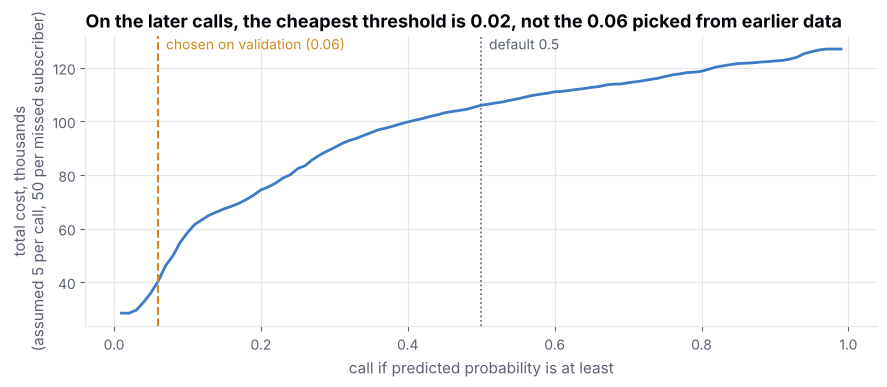

In [13]:
curve = cost_curve(y_test, p_test, COST_FP, COST_FN)
best_test_t = float(curve.loc[curve["cost"].idxmin(), "threshold"])
print(f"with hindsight, the cheapest threshold on the test calls is {best_test_t:.2f} (cost {curve['cost'].min():,.0f})")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(curve["threshold"], curve["cost"] / 1000, color=COOL)
ax.axvline(t_star, color=ACCENT, linestyle="--", linewidth=1.5)
ax.axvline(0.5, color=INK_2, linestyle=":", linewidth=1.2)
ax.text(t_star, ax.get_ylim()[1], f"  chosen on validation ({t_star:.2f})", color=ACCENT, va="top", fontsize=10)
ax.text(0.5, ax.get_ylim()[1], "  default 0.5", color=INK_2, va="top", fontsize=10)
ax.set(title=f"On the later calls, the cheapest threshold is {best_test_t:.2f}, not the {t_star:.2f} picked from earlier data",
       xlabel="call if predicted probability is at least",
       ylabel=f"total cost, thousands\n(assumed {COST_FP} per call, {COST_FN} per missed subscriber)")
fig.tight_layout()
save(fig, "bank_cost_threshold.png");

This is the weakest result in the repo, and I'd rather say it plainly. At my assumed costs the model policy costs 40,395 on the later calls, and simply calling everyone costs 28,490. The threshold of 0.06 was picked on a validation block that converted at 12.7%. By the test period conversion was 30.8%, and when almost a third of people say yes and a miss costs ten times a call, it pays to call nearly everyone. The default 0.5 cut-off is far worse than either (106,035), because it misses 2,078 of the 2,540 subscribers. Even with hindsight, the cheapest threshold on the test calls is 0.02, which costs 28,435, only 55 less than calling everyone.

### How much does this depend on my cost guess?

Five cost pairs. For each one the threshold is picked on the validation block and scored on the test calls.

In [14]:
pairs = [(5, 25), (5, 50), (5, 100), (2, 50), (10, 50)]
sens = cost_sensitivity(y_val, p_val, y_test, p_test, pairs)
sens.round(3)

,cost_fp,cost_fn,threshold,calls,cost_model,cost_default_0.5,cost_call_everyone,saving_vs_call_everyone
0,5,25,0.08,3859,30175.0,54085.0,28490.0,-0.059
1,5,50,0.06,5460,40395.0,106035.0,28490.0,-0.418
2,5,100,0.01,8238,28490.0,209935.0,28490.0,0.000
3,2,50,0.01,8238,11396.0,104754.0,11396.0,0.000
4,10,50,0.08,3859,60350.0,108170.0,56980.0,-0.059


Under none of these does the model save money compared with calling everyone. At best it ties, because the chosen threshold drops to 0.01 and it calls everyone anyway. When a wasted call costs 5 and a miss 25, or a call 10 and a miss 50, it is about 6% worse. So the model is not ready to decide who to call. It might still be useful for ordering the call list inside a month, where its within-month ROC-AUC is about 0.64, but I would want a fresh month of labelled calls to recalibrate before trusting any cut-off.

## What the chosen model relies on

Permutation importance on the test calls: shuffle one column and see how much ROC-AUC drops. It works on raw columns and on data the model has not seen. Correlated columns share credit, so a low score for one of a pair does not mean it is useless.

In [15]:
perm = permutation_importance(fitted[best_name], X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=SEED, n_jobs=1)
imp = (pd.DataFrame({"feature": X_test.columns, "drop_in_roc_auc": perm.importances_mean, "sd": perm.importances_std})
       .query("feature not in @best_drop")  # columns the model never sees score exactly 0
       .sort_values("drop_in_roc_auc", ascending=False, ignore_index=True))
imp.head(10)

,feature,drop_in_roc_auc,sd
0,previously_contacted,0.095489,0.003572
1,month,0.048427,0.004046
2,job,0.012420,0.001171
3,contact,0.008840,0.001851
4,poutcome,0.008549,0.001698
5,campaign,0.003514,0.000419
6,default,0.002824,0.000472
7,education,0.001647,0.000680
8,day_of_week,0.001186,0.000964
9,housing,-0.000019,0.000143


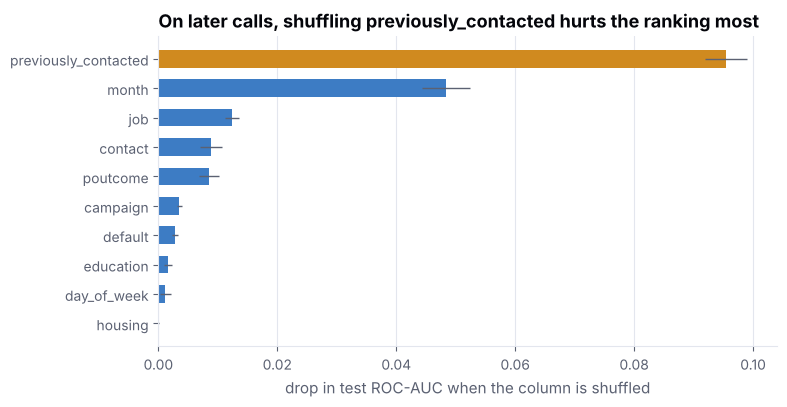

In [16]:
top = imp.head(10).iloc[::-1]
colors = [ACCENT if i == len(top) - 1 else COOL for i in range(len(top))]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top["feature"], top["drop_in_roc_auc"], xerr=top["sd"], color=colors, height=0.6,
        error_kw={"ecolor": INK_2, "elinewidth": 1})
ax.set(title=f"On later calls, shuffling {top['feature'].iloc[-1]} hurts the ranking most",
       xlabel="drop in test ROC-AUC when the column is shuffled")
ax.set_xlim(left=0)
ax.grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "bank_permutation_importance.png");

Having been contacted in an earlier campaign is by far the strongest signal, followed by month. Job, contact type and the outcome of the previous campaign add a little. Education, marital status and day of week add almost nothing.

## For reference: the random split

This is the setup most write-ups of this dataset use, and the one I started with. It answers "how well does this rank clients from the same period", which is easier. I keep it because it is a fair way to compare model types and to look at imbalance and calibration, as long as nobody reads the numbers as next-quarter performance.

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
same_period = {"logistic": "logistic", "logistic (balanced)": "logistic (balanced)",
               "random forest": "random forest", "lightgbm": "lightgbm"}
cv_rows, test_rows, random_proba = [], {}, {}
for name, kind in same_period.items():
    s = cross_validate(make_model(kind), Xr_train, yr_train, cv=cv, scoring=scoring)
    cv_rows.append({"model": name, "cv_roc_auc": s["test_roc_auc"].mean(), "cv_roc_auc_sd": s["test_roc_auc"].std(),
                    "cv_pr_auc": s["test_pr_auc"].mean(), "cv_brier": -s["test_brier"].mean()})
    p = make_model(kind).fit(Xr_train, yr_train).predict_proba(Xr_test)[:, 1]
    random_proba[name] = p
    test_rows[name] = {"test_roc_auc": roc_auc_score(yr_test, p), "test_pr_auc": average_precision_score(yr_test, p),
                       "test_brier": brier_score_loss(yr_test, p)}
random_df = pd.DataFrame(cv_rows).set_index("model").join(pd.DataFrame(test_rows).T)
random_df

,cv_roc_auc,cv_roc_auc_sd,cv_pr_auc,cv_brier,test_roc_auc,test_pr_auc,test_brier
model,,,,,,,
logistic,0.788901,0.006652,0.449569,0.078886,0.800846,0.465260,0.076863
logistic (balanced),0.789611,0.005424,0.443892,0.165119,0.800988,0.459701,0.161640
random forest,0.791812,0.003617,0.468896,0.077206,0.809188,0.493636,0.074357
lightgbm,0.794807,0.003652,0.469342,0.077262,0.813783,0.494743,0.074119


On the random split, the tree models edge out logistic regression (test ROC-AUC 0.814 for LightGBM, 0.801 for logistic), and random forest and LightGBM are tied within fold noise.

The two logistic rows show what `class_weight="balanced"` does. Ranking barely changes (0.801 either way), but the Brier score goes from 0.077 to 0.162 because the probabilities get pushed up and stop meaning what they say. That's the general pattern with reweighting or SMOTE. They move the default 0.5 cut-off but add no information, so I keep honest probabilities and handle the imbalance in the threshold.

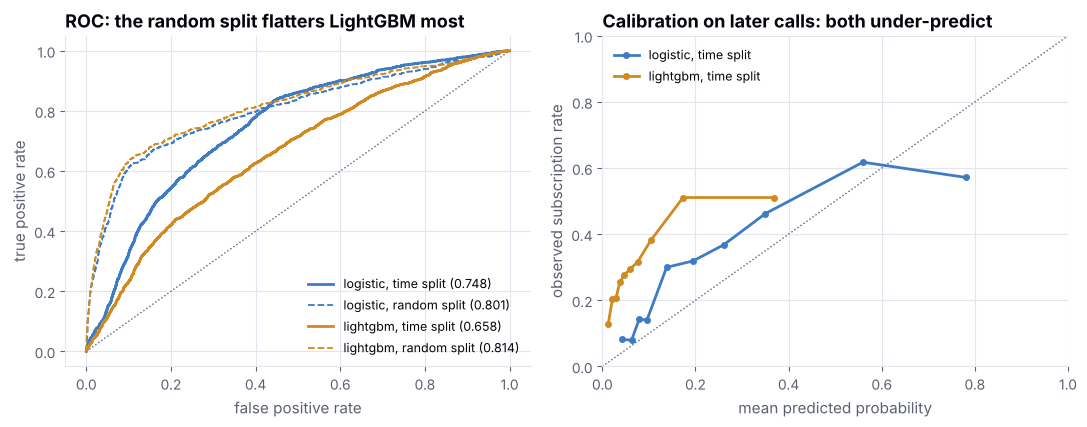

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=INK_2, linestyle=":", linewidth=1)
for name, color in [("logistic", COOL), ("lightgbm", ACCENT)]:
    fpr, tpr, _ = roc_curve(y_test, p_time[name])
    ax.plot(fpr, tpr, color=color, label=f"{name}, time split ({time_df.loc[name, 'roc_auc']:.3f})")
    fpr, tpr, _ = roc_curve(yr_test, random_proba[name])
    ax.plot(fpr, tpr, color=color, linestyle="--", linewidth=1.3, label=f"{name}, random split ({random_df.loc[name, 'test_roc_auc']:.3f})")
ax.set(title="ROC: the random split flatters LightGBM most", xlabel="false positive rate", ylabel="true positive rate")
ax.legend(loc="lower right", fontsize=9)
ax = axes[1]
ax.plot([0, 1], [0, 1], color=INK_2, linestyle=":", linewidth=1)
for name, color in [("logistic", COOL), ("lightgbm", ACCENT)]:
    frac, mean_pred = calibration_curve(y_test, p_time[name], n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, marker="o", markersize=4, color=color, label=f"{name}, time split")
ax.set(title="Calibration on later calls: both under-predict", xlabel="mean predicted probability",
       ylabel="observed subscription rate", xlim=(0, 1), ylim=(0, 1))
ax.legend(loc="upper left", fontsize=9)
fig.tight_layout()
save(fig, "bank_roc_pr.png");

The left chart puts the two splits side by side for the same two model types. Solid lines are the time split, dashed the random split. The right chart is calibration on the later calls, which is where the time split hurts most.

### SHAP on the random-split LightGBM

I keep this to show what the random-split model leans on. SHAP splits each prediction into per-feature contributions, and the mean absolute value gives a ranking. 2,000 test rows to keep it fast.

In [19]:
lgb_pipe = make_model("lightgbm").fit(Xr_train, yr_train)
X_sample = Xr_test.sample(2000, random_state=SEED)
X_enc = pd.DataFrame(lgb_pipe.named_steps["pre"].transform(X_sample),
                     columns=lgb_pipe.named_steps["pre"].get_feature_names_out(), index=X_sample.index)
explainer = shap.TreeExplainer(lgb_pipe.named_steps["clf"])
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)  # shap notes a change in its LightGBM output format
    sv = explainer.shap_values(X_enc)
sv = sv[1] if isinstance(sv, list) else sv
shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=X_enc.columns).sort_values(ascending=False)
for col in ["nr_employed", "euribor3m"]:
    r = np.corrcoef(X_enc[col], sv[:, X_enc.columns.get_loc(col)])[0, 1]
    print(f"correlation between {col} and its SHAP value: {r:.3f}")
shap_imp.head(8).to_frame("mean |SHAP| (log-odds)")

correlation between nr_employed and its SHAP value: -0.648
correlation between euribor3m and its SHAP value: -0.717


,mean |SHAP| (log-odds)
nr_employed,0.288295
euribor3m,0.232568
contact,0.183180
emp_var_rate,0.102572
campaign,0.098960
cons_conf_idx,0.094328
age,0.084958
day_of_week,0.081991


On the random split the top two features are `nr_employed` and `euribor3m`, and both push the probability down as they rise. In plain terms the model learned that calls made when rates and employment were low converted more. That is true, but it is about when the call happened, not who the client is, and it is exactly the part that fell apart on the time split. On the time split, the no-macro model leans on whether the client had been contacted before, which is about the client.

In [20]:
(RESULTS / "classification.json").write_text(json.dumps({
    "split": "time ordered, first 80% of calls train, last 20% test",
    "n_train": len(X_train), "n_test": len(X_test),
    "train_months": [f"{months_train.min():%Y-%m}", f"{months_train.max():%Y-%m}"],
    "test_months": [f"{months_test.min():%Y-%m}", f"{months_test.max():%Y-%m}"],
    "positive_rate_train": float(y_train.mean()), "positive_rate_test": float(y_test.mean()),
    "cv_time_series": cv_time.to_dict(orient="index"),
    "test_time_split": time_df.to_dict(orient="index"),
    "random_vs_time_roc_auc": gap.to_dict(orient="index"),
    "decision_model": best_name,
    "cost_fp": COST_FP, "cost_fn": COST_FN, "threshold": t_star,
    "policies": policy_df.reset_index().to_dict(orient="records"),
    "cost_sensitivity": sens.to_dict(orient="records"),
    "top_permutation_features": imp.head(5)["feature"].tolist(),
    "random_split_reference": random_df.to_dict(orient="index"),
}, indent=2, default=float))
print("saved results/classification.json")

saved results/classification.json
